# GCAM produces a result file; MARIO interprets it as a mix shock

Follow one actual GCAM output value all the way to a coefficient read back from MARIO.
The physical input files are real study results. The small IO database uses **fictional
inventories and baseline demand** so this example runs quickly; its footprints are
illustrative, not the paper's results. No GCAM installation or database download is needed.

[Input contract](../docs/input-contract.md) · [Equations](../docs/from-gcam-to-mario.md) ·
[Sources](../examples/gcam-output/README.md) · [Full EXIOBASE route](../docs/database-preparation.md)


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mario
from gcam_mario import Projections, demo_database, apply_mix_shock, explain_coefficients
from gcam_mario.results import footprints, export_run

ROOT = Path.cwd()
if not (ROOT / "config" / "variables.json").is_file():
    ROOT = ROOT.parent
mario.set_log_verbosity("error")
pd.set_option("display.precision", 12)
SCENARIO, YEAR = "NDC_LTT_CBAM", 2030


## 1. This is the file exported from GCAM results

`electricity.csv` retains the physical values and column layout of the published GCAM export,
filtered to the two EU regions and the nine electricity variables. Extraction does **not**
calculate shares. `Unit` is `EJ/yr`, and each year column is a generation quantity.

The table below shows every term used in the EU-15 denominator. Change scenario/year above
to select another available GCAM result; this does not rerun the GCAM model.


In [2]:
electricity_file = ROOT / "examples" / "gcam-output" / "electricity.csv"
steel_file = ROOT / "examples" / "gcam-output" / "steel.csv"
raw = pd.read_csv(electricity_file, float_precision="round_trip")
raw_rows = raw[(raw.Scenario == SCENARIO) & (raw.Region == "EU-15")]
raw_rows[["Scenario", "Region", "Variable", "Unit", str(YEAR)]]


,Scenario,Region,Variable,Unit,2030
27,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Biomass,EJ/yr,0.1196873587
28,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Coal,EJ/yr,0.0164928200
29,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Gas,EJ/yr,0.0387851200
30,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Geothermal,EJ/yr,0.1868060000
31,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Hydro,EJ/yr,1.1600000000
32,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Nuclear,EJ/yr,2.7675830000
33,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Oil,EJ/yr,0.0169215000
34,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Solar,EJ/yr,2.7124690520
35,NDC_LTT_CBAM,EU-15,Secondary Energy|Electricity|Wind,EJ/yr,4.5116719100


## 2. MARIO's adapter reads names, units and physical quantities

The explicit concordance maps `Secondary Energy|Electricity|Wind` to MARIO's `Wind` commodity.
The reader divides each physical quantity by the sum of the nine technologies in the same
scenario, region and year. **EJ/yr cancels: the result is a dimensionless share.**
`SourceRow` identifies the original CSV line, including its header as line 1.


In [3]:
inputs = Projections(electricity_export=electricity_file, steel_export=steel_file)
electricity_selection = inputs.select(SCENARIO, YEAR, kinds=("electricity",))
trace = electricity_selection.trace.query("Region == 'EU-15'")
trace[["SourceFile", "SourceRow", "Variable", "MarioItem", "Value", "Unit", "GroupTotal", "Share"]]


,SourceFile,SourceRow,Variable,MarioItem,Value,Unit,GroupTotal,Share
9,electricity.csv,29,Secondary Energy|Electricity|Biomass,Bioenergy,0.1196873587,EJ/yr,11.5304167607,0.010380141601
10,electricity.csv,30,Secondary Energy|Electricity|Coal,Coal,0.0164928200,EJ/yr,11.5304167607,0.001430375011
11,electricity.csv,31,Secondary Energy|Electricity|Gas,Gas,0.0387851200,EJ/yr,11.5304167607,0.003363722301
12,electricity.csv,32,Secondary Energy|Electricity|Geothermal,Other Renewables,0.1868060000,EJ/yr,11.5304167607,0.016201149002
13,electricity.csv,33,Secondary Energy|Electricity|Hydro,Hydro,1.1600000000,EJ/yr,11.5304167607,0.100603475492
14,electricity.csv,34,Secondary Energy|Electricity|Nuclear,Nuclear,2.7675830000,EJ/yr,11.5304167607,0.240024541822
15,electricity.csv,35,Secondary Energy|Electricity|Oil,Other Fossil,0.0169215000,EJ/yr,11.5304167607,0.001467553199
16,electricity.csv,36,Secondary Energy|Electricity|Solar,Solar,2.7124690520,EJ/yr,11.5304167607,0.235244667066
17,electricity.csv,37,Secondary Energy|Electricity|Wind,Wind,4.5116719100,EJ/yr,11.5304167607,0.391284374506


In [4]:
wind = trace.loc[trace.MarioItem == "Wind"].iloc[0]
print(f"GCAM Wind: {wind.Value:.12g} {wind.Unit}")
print(f"GCAM total electricity: {wind.GroupTotal:.12g} {wind.Unit}")
print(f"Target Wind share = {wind.Value:.12g} / {wind.GroupTotal:.12g} = {wind.Share:.12g}")
assert np.isclose(trace.Share.sum(), 1)


GCAM Wind: 4.51167191 EJ/yr
GCAM total electricity: 11.5304167607 EJ/yr
Target Wind share = 4.51167191 / 11.5304167607 = 0.391284374506


## 3. Apply that share to MARIO's existing total

For each supplying region and consuming activity, sum its electricity coefficients in `u`.
Then redistribute that original total using the GCAM shares. Apply the same rule to commodity
final demand `Yc`. Total electricity in every column is preserved; the source technologies change.
Dedicated electricity for hydrogen electrolysis is excluded by default, as in the old script.

We create an independent scenario from `baseline`. The table below reads the **actual** values
back from MARIO and checks them against `share × original group total`.


In [5]:
db = demo_database()
electricity_report = apply_mix_shock(db, electricity_selection, name="electricity_only", steel=False)
electricity_changes = explain_coefficients(db, electricity_selection, scenario="electricity_only")
use_changes = electricity_changes.query("matrix == 'u' and region == 'EU-15'")
np.testing.assert_allclose(use_changes.after, use_changes.share_times_original_total, atol=1e-14)
use_changes[["item", "unit", "gcam_share", "original_group_total", "before", "share_times_original_total", "after"]]


,item,unit,gcam_share,original_group_total,before,share_times_original_total,after
9,Bioenergy,TJ/tonnes,0.010380141601,0.001275,0.000141666667,0.000013234681,0.000013234681
10,Coal,TJ/tonnes,0.001430375011,0.001275,0.000141666667,0.000001823728,0.000001823728
11,Gas,TJ/tonnes,0.003363722301,0.001275,0.000141666667,0.000004288746,0.000004288746
12,Hydro,TJ/tonnes,0.100603475492,0.001275,0.000141666667,0.000128269431,0.000128269431
13,Nuclear,TJ/tonnes,0.240024541822,0.001275,0.000141666667,0.000306031291,0.000306031291
14,Other Fossil,TJ/tonnes,0.001467553199,0.001275,0.000141666667,0.000001871130,0.000001871130
15,Other Renewables,TJ/tonnes,0.016201149002,0.001275,0.000141666667,0.000020656465,0.000020656465
16,Solar,TJ/tonnes,0.235244667066,0.001275,0.000141666667,0.000299936951,0.000299936951
17,Wind,TJ/tonnes,0.391284374506,0.001275,0.000141666667,0.000498887577,0.000498887577


In [6]:
wind_change = use_changes.loc[use_changes.item == "Wind"].iloc[0]
print(f"New Wind coefficient = {wind_change.gcam_share:.12g} × {wind_change.original_group_total:.12g}")
print(f"Expected: {wind_change.share_times_original_total:.12g} {wind_change.unit}")
print(f"Read back from MARIO: {wind_change.after:.12g} {wind_change.unit}")
print("Conservation over ALL affected columns:")
electricity_report.checks


New Wind coefficient = 0.391284374506 × 0.001275
Expected: 0.000498887577495 TJ/tonnes
Read back from MARIO: 0.000498887577495 TJ/tonnes
Conservation over ALL affected columns:


[{'kind': 'electricity',
  'region': 'EU-12',
  'max_use_total_change': 1.734723475976807e-18,
  'max_final_demand_total_change': 0.0},
 {'kind': 'electricity',
  'region': 'EU-15',
  'max_use_total_change': 4.336808689942018e-19,
  'max_final_demand_total_change': 0.0}]

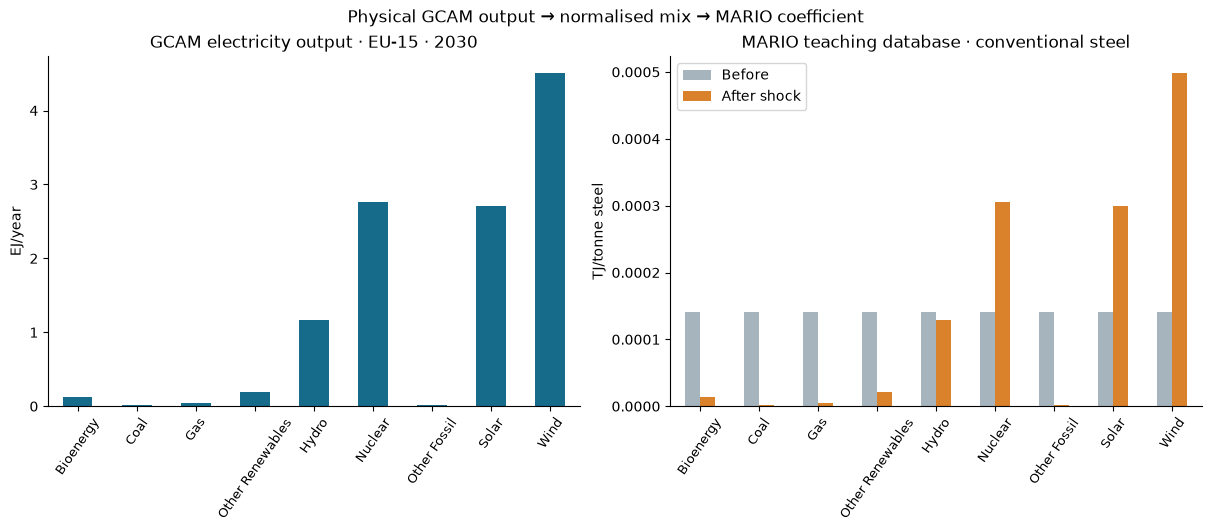

In [7]:
order = list(trace.MarioItem)
physical = trace.set_index("MarioItem").loc[order, "Value"]
coefficients = use_changes.set_index("item").loc[order]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), layout="constrained")
physical.plot.bar(ax=axes[0], color="#176b8a", rot=55)
axes[0].set(title=f"GCAM electricity output · EU-15 · {YEAR}", ylabel="EJ/year", xlabel="")
coefficients[["before", "after"]].rename(columns={"before": "Before", "after": "After shock"}).plot.bar(
    ax=axes[1], color=["#a5b4bd", "#d9822b"], rot=55)
axes[1].set(title="MARIO teaching database · conventional steel", ylabel="TJ/tonne steel", xlabel="")
fig.suptitle("Physical GCAM output → normalised mix → MARIO coefficient")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=9)
(ROOT / "docs" / "assets").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "docs" / "assets" / "gcam-to-coefficient.png", dpi=150)
plt.show()


## 4. Steel: physical production becomes supplier shares in `s`

The regional steel export uses `Mt/yr`. Four GCAM scrap/finishing variables map to the same
MARIO secondary-steel activity: their physical quantities are **summed before normalisation**.
The regional export comes from the study maintainer's `SteelProdTech` sheet; its EU-12 + EU-15
totals match all 504 published aggregate values. The public supplement itself provides EU27 steel
totals. See the linked provenance for the source distinction.


In [8]:
steel_selection = inputs.select(SCENARIO, YEAR, kinds=("steel",))
steel_trace = steel_selection.trace.query("Region == 'EU-15'")
steel_trace[steel_trace.Variable.str.contains("EAF_scrap")][
    ["Variable", "Value", "Unit", "MarioItem", "MappedValue", "GroupTotal", "ContributionShare", "Share"]]


,Variable,Value,Unit,MarioItem,MappedValue,GroupTotal,ContributionShare,Share
35,Production|Steel|EAF_scrap_bio_NG_finish,12.0415,Mt/yr,Re-processing of secondary steel into new steel,84.7679,114.574834,0.105097250239,0.739847460743
36,Production|Steel|EAF_scrap_bio_elec_finish,0.0000,Mt/yr,Re-processing of secondary steel into new steel,84.7679,114.574834,0.000000000000,0.739847460743
37,Production|Steel|EAF_scrap_fossil_NG_finish,72.7264,Mt/yr,Re-processing of secondary steel into new steel,84.7679,114.574834,0.634750210504,0.739847460743
38,Production|Steel|EAF_scrap_fossil_elec_finish,0.0000,Mt/yr,Re-processing of secondary steel into new steel,84.7679,114.574834,0.000000000000,0.739847460743


Each target steel-activity share multiplies the original total market share of the selected
18 routes in the regional steel commodity column. Their inventories remain in the database.
This changes the average steel mix; it does not set total demand to the GCAM production level.


In [9]:
steel_report = apply_mix_shock(db, steel_selection, name="steel_only", electricity=False)
steel_changes = explain_coefficients(db, steel_selection, scenario="steel_only")
np.testing.assert_allclose(steel_changes.after, steel_changes.share_times_original_total, atol=1e-14)
steel_changes[["region", "item", "gcam_share", "original_group_total", "before", "after"]]


,region,item,gcam_share,original_group_total,before,after
0,EU-12,AEL-EAF,0.000000000000,1.0,0.00625,0.000000000000
1,EU-12,BF-BOF-BECCSmax,0.013361264039,1.0,0.00625,0.013361264039
2,EU-12,BF-BOF-BECCSmin,0.014898232101,1.0,0.00625,0.014898232101
3,EU-12,BF-BOF-CCS-73%,0.017995912713,1.0,0.00625,0.017995912713
4,EU-12,BF-BOF-CCS-86%,0.017933683803,1.0,0.00625,0.017933683803
5,EU-12,DRI-EAF-BECCS,0.005841373356,1.0,0.00625,0.005841373356
6,EU-12,DRI-EAF-COAL-CCS,0.002000301016,1.0,0.00625,0.002000301016
7,EU-12,DRI-EAF-H2,0.004494275164,1.0,0.00625,0.004494275164
8,EU-12,DRI-EAF-NG,0.013895406037,1.0,0.00625,0.013895406037
9,EU-12,DRI-EAF-NG-CCS,0.016687499682,1.0,0.00625,0.016687499682


## 5. Combine the two shocks and compare footprints

Each scenario starts independently from the same baseline. The combined scenario changes both
mixes. These illustrative footprints use real GCAM shares with fictional IO inventories.
The full-database route uses exactly the same adapter with extended EXIOBASE inventories.


In [10]:
combined_selection = inputs.select(SCENARIO, YEAR)
combined_report = apply_mix_shock(db, combined_selection, name="combined")
comparison = footprints(db, ["baseline", "electricity_only", "steel_only", "combined"], ["EU-12", "EU-15"])
comparison.pivot(index="region", columns="scenario", values="ghg_tco2eq_per_tonne_steel")


scenario,baseline,combined,electricity_only,steel_only
region,,,,
EU-12,1.2273285,0.368407329086,1.149661288075,0.501742075653
EU-15,1.2273285,0.302504567735,1.140936558419,0.455360412326


## 6. Keep the whole interpretation with the results

The output saves the original CSV row and physical value, concordance, normalisation, actual
coefficient edits, conservation checks and footprints. This cell explicitly replaces the
previous output of this notebook's example. Use a different directory for your own experiments.


In [11]:
output = export_run(db, [electricity_report, steel_report, combined_report],
    ROOT / "outputs" / "notebook_example", database_kind="demo", overwrite=True)
print(output.relative_to(ROOT))
print(sorted(p.name for p in output.iterdir()))


outputs/notebook_example
['coefficients_before_after.csv', 'footprints.csv', 'input_interpretation.csv', 'mixes.csv', 'run.json']


## Use the same mechanism on extended EXIOBASE

The small example above needs no data download. To use the published extended database,
run these commands separately after reading the preparation guide:

```bash
gcam-mario prepare
gcam-mario run --scenario NDC_LTT_CBAM --year 2030 --offline
```

The first preparation may download 1.78 GB. It aggregates EU regions, adds the GHG account and
saves a reusable bundle. This mix workflow retains background inventories, demand and trade;
it does not claim a full rerun of GCAM or every paper result.
